In [2]:
# Data Analysis:
import pandas as pd
import numpy as np
from missingno import matrix

# Modeling:
import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families.links import logit
from sklearn.metrics import roc_auc_score

In [3]:
hotel_cancellations_raw_df = pd.read_csv('data/hotel_booking.csv')

In [4]:
cancellation_counts = hotel_cancellations_raw_df['is_canceled'].value_counts().reset_index()
cancellation_counts.columns = ['is_canceled', 'n']
cancellation_counts['prop'] = cancellation_counts['n'] / cancellation_counts['n'].sum()

# Display the result
cancellation_counts

,is_canceled,n,prop
0,0,75166,0.629584
1,1,44224,0.370416


In [5]:
#Assumes 200 a night and 3.4 average stay days
cost = 44224 * 200 * 3.4
formatted_cost = "${:,.0f}".format(cost)
formatted_cost

'$30,072,320'

In [6]:
ten_percent_cost = 0.1 * cost
formatted_ten_percent_cost = "${:,.0f}".format(ten_percent_cost)
formatted_ten_percent_cost

'$3,007,232'

In [7]:
# 1.0 DATA PROCESSING -----

# * Basic Feature Engineering -----

hotel_cancellations_df = hotel_cancellations_raw_df.copy()

# Adding new features
hotel_cancellations_df['total_stay'] = hotel_cancellations_df['stays_in_weekend_nights'] + hotel_cancellations_df['stays_in_week_nights']

hotel_cancellations_df['total_guests'] = hotel_cancellations_df['adults'] + hotel_cancellations_df['children'] + hotel_cancellations_df['babies']

hotel_cancellations_df['different_room_assigned'] = (hotel_cancellations_df['reserved_room_type'] != hotel_cancellations_df['assigned_room_type']).astype(int)


In [8]:
# Dropping the original columns
hotel_cancellations_df.drop(
    columns=[
        'stays_in_weekend_nights',
        'stays_in_week_nights',
        'adults',
        'children',
        'babies',
        'reserved_room_type',
        'assigned_room_type'
    ],
    inplace=True
)

hotel_cancellations_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   meal                            119390 non-null  str    
 8   country                         118902 non-null  str    
 9   market_segment                  119390 non-null  str    
 10  distribution_channel            119390 non-null  str    
 11  is_repeated_guest               119390 non-null  int64  
 12  previous_cancellations     

<Axes: >

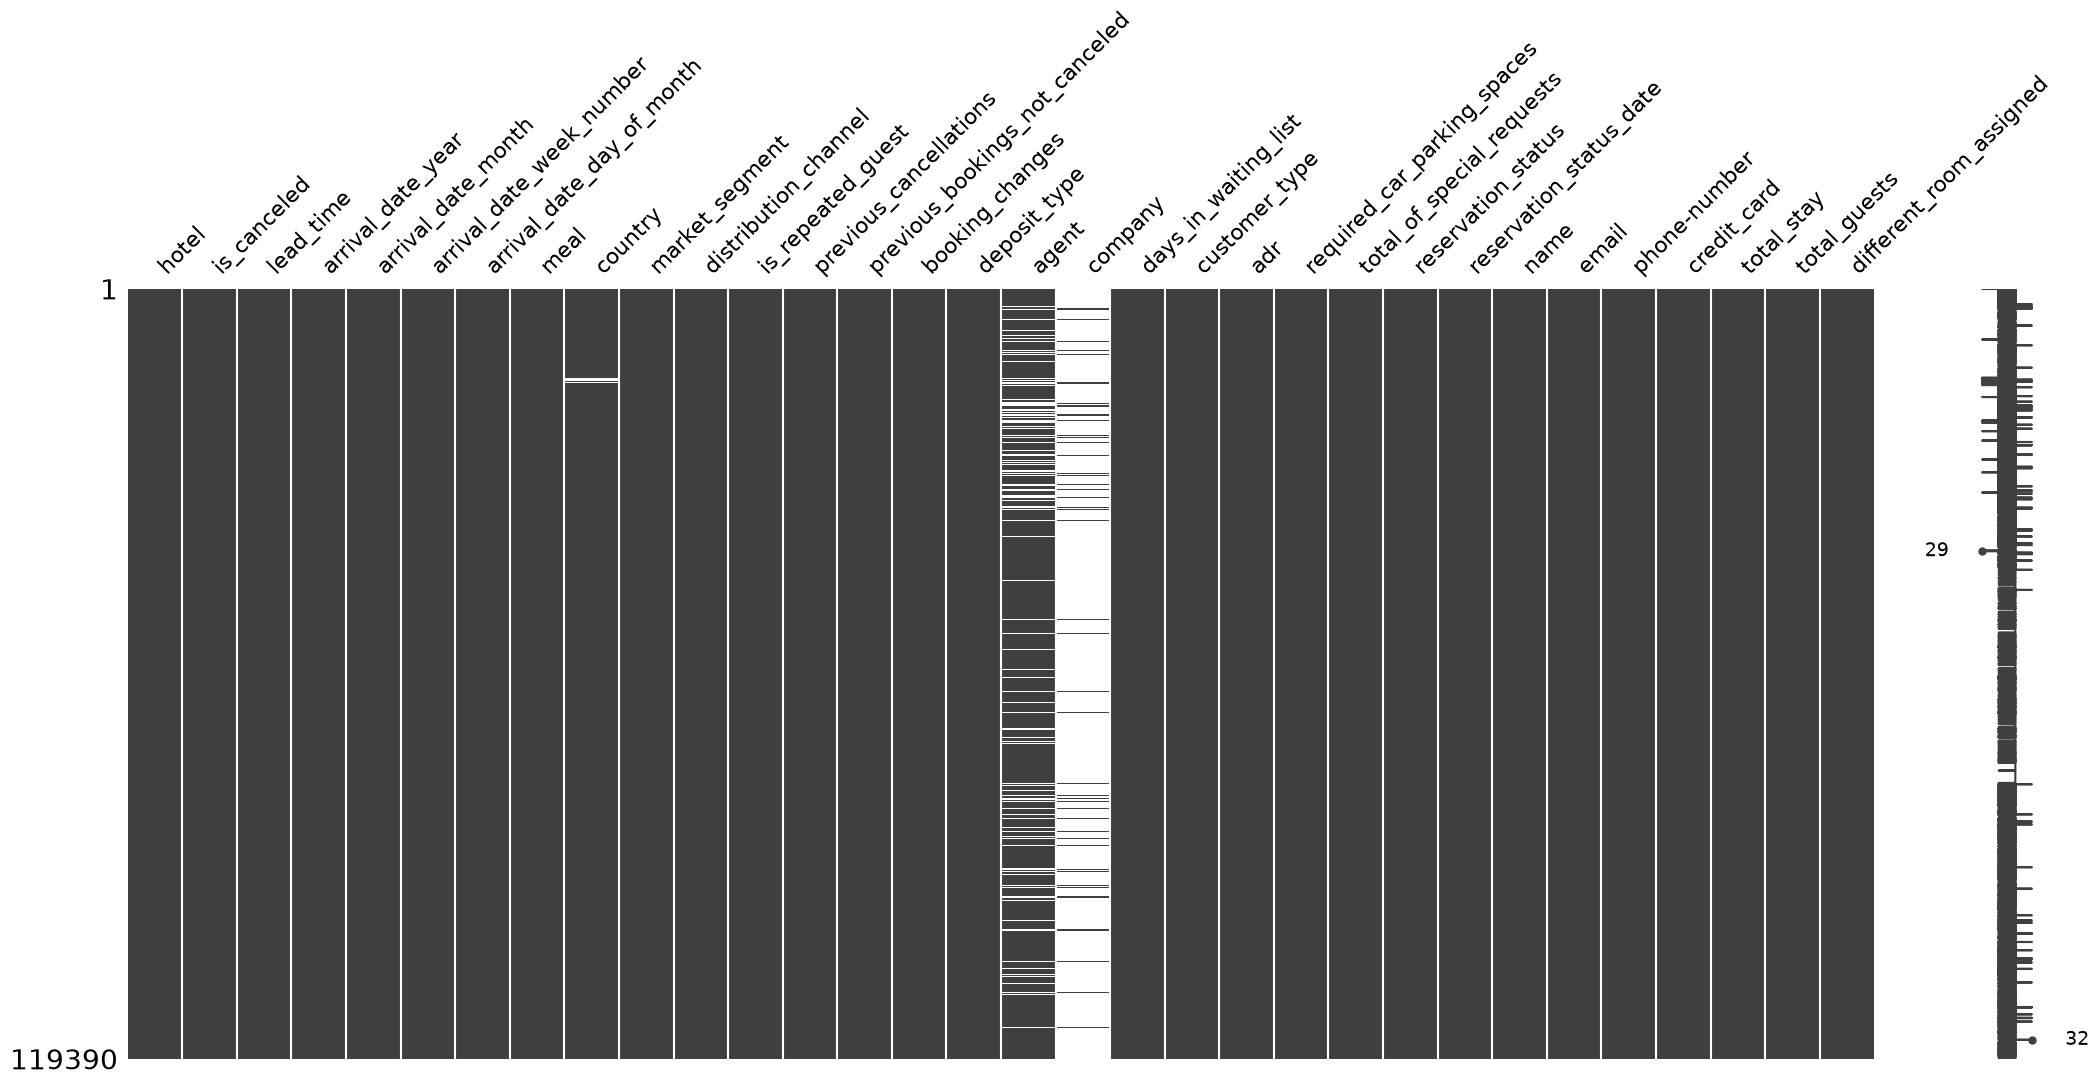

In [9]:
# * Fix Missing -----

# Plot missing values
matrix(hotel_cancellations_df)



In [10]:
# Count by country with sorting
country_count = hotel_cancellations_df['country'].value_counts().reset_index()

country_count.columns = ['country', 'count']
country_count



,country,count
0,PRT,48590
1,GBR,12129
2,FRA,10415
3,ESP,8568
4,DEU,7287
...,...,...
172,NCL,1
173,KIR,1
174,SDN,1
175,ATF,1


In [11]:
# Fix missing values and drop columns (we are dropping the columns that the chart showed were missing most of their values)
hotel_cancellations_df = hotel_cancellations_df.drop(columns=['company', 'agent'])

# PRT is Portugal > Most of the people are coming from there so fill in the rest with that
hotel_cancellations_df['country'] = hotel_cancellations_df['country'].fillna('PRT')

hotel_cancellations_df.dropna(inplace=True)



In [12]:
# * Drop Unneeded Columns -----

hotel_cancellations_df.info()

hotel_cancellations_df.drop(columns=['reservation_status_date'], inplace=True)

<class 'pandas.DataFrame'>
Index: 119386 entries, 0 to 119389
Data columns (total 30 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119386 non-null  str    
 1   is_canceled                     119386 non-null  int64  
 2   lead_time                       119386 non-null  int64  
 3   arrival_date_year               119386 non-null  int64  
 4   arrival_date_month              119386 non-null  str    
 5   arrival_date_week_number        119386 non-null  int64  
 6   arrival_date_day_of_month       119386 non-null  int64  
 7   meal                            119386 non-null  str    
 8   country                         119386 non-null  str    
 9   market_segment                  119386 non-null  str    
 10  distribution_channel            119386 non-null  str    
 11  is_repeated_guest               119386 non-null  int64  
 12  previous_cancellations          

In [13]:
import pytimetk as tk
hotel_cancellations_df.glimpse()

c:\Users\guske\Desktop\Python_Projects\Python_Projects_3\modern_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-27 16:26:37,203	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


<class 'pandas.DataFrame'>: 119386 rows of 29 columns
hotel:                           str               ['Resort Hotel', 'Res ...
is_canceled:                     int64             [0, 0, 0, 0, 0, 0, 0, ...
lead_time:                       int64             [342, 737, 7, 13, 14, ...
arrival_date_year:               int64             [2015, 2015, 2015, 20 ...
arrival_date_month:              str               ['July', 'July', 'Jul ...
arrival_date_week_number:        int64             [27, 27, 27, 27, 27,  ...
arrival_date_day_of_month:       int64             [1, 1, 1, 1, 1, 1, 1, ...
meal:                            str               ['BB', 'BB', 'BB', 'B ...
country:                         str               ['PRT', 'PRT', 'GBR', ...
market_segment:                  str               ['Direct', 'Direct',  ...
distribution_channel:            str               ['Direct', 'Direct',  ...
is_repeated_guest:               int64             [0, 0, 0, 0, 0, 0, 0, ...
previous_cancellations

In [14]:
# Save pre-processes data as new cleaned csv
hotel_cancellations_df.to_csv("data/hotel_cancellations_clean.csv",index=False)

In [15]:
# 2.0 CORRELATION (LEVEL 1: ASSOCIATION) -----
# - We need to test correlation (if there is no correlation it is hard to imagine a causal relation). Will use a correlation funnel.

hotel_cancellations_df = pd.read_csv("data/hotel_cancellations_clean.csv")

In [16]:
# * Safe Manual Binarization (Protecting Numeric Columns) -----

df_binarized = hotel_cancellations_df.copy()

# 1. Drop high-cardinality columns, but ONLY if they are text/object columns (let numeric columns through to be binned!)
max_unique_allowed = 50
cols_to_drop = [
    col for col in df_binarized.columns 
    if df_binarized[col].nunique() > max_unique_allowed 
    and col != 'is_canceled' 
    and not pd.api.types.is_numeric_dtype(df_binarized[col])
]
df_binarized.drop(columns=cols_to_drop, inplace=True)

print(f"Dropped high-cardinality text columns: {cols_to_drop}")

# 2. Now bin ALL numeric columns safely (including lead_time!)
numeric_cols = df_binarized.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns
for col in numeric_cols:
    if col != 'is_canceled':
        try:
            df_binarized[col] = pd.qcut(df_binarized[col], q=4, labels=False, duplicates='drop')
            df_binarized[col] = f"{col}_bin_" + df_binarized[col].astype(str)
        except Exception:
            pass

# 3. One-hot encode the rest
df_binarized = pd.get_dummies(df_binarized, prefix_sep="__", dtype=int)

print(f"Final binarized shape with lead_time included: {df_binarized.shape}")

Dropped high-cardinality text columns: ['country', 'name', 'email', 'phone-number', 'credit_card']
Final binarized shape with lead_time included: (119386, 75)


In [17]:
# * Correlate -----
df_correlated = df_binarized.correlate(target="is_canceled")

df_correlated.head(10)



,feature,bin,correlation
0,is_canceled,None,1.000000
66,reservation_status,Check-Out,-1.000000
65,reservation_status,Canceled,0.978433
51,deposit_type,Non Refund,0.481488
50,deposit_type,No Deposit,-0.477942
3,lead_time,lead_time_bin_0,-0.270429
38,market_segment,Groups,0.221886
6,lead_time,lead_time_bin_3,0.219856
44,distribution_channel,TA/TO,0.176056
37,market_segment,Direct,-0.154420


In [18]:
# * Visualize ----- Was not able to get country or previous_cancellation in the data
df_correlated.plot_correlation_funnel()

In [19]:
# * Subset features that describe the system ----- 

# Subset features -> Get rid of non causational high correlation column
hotel_cancellations_subset_df = hotel_cancellations_df.drop(columns=['reservation_status'])

# Selecting specific columns -> only select high correlation ones to just leave these remaining columns
hotel_cancellations_subset_df = hotel_cancellations_subset_df[[
    'is_canceled', 'deposit_type', 'country', 'previous_cancellations',
    'lead_time', 'total_of_special_requests', 'different_room_assigned',
    'market_segment', 'required_car_parking_spaces', 'distribution_channel',
    'hotel', 'customer_type', 'previous_bookings_not_canceled',
    'is_repeated_guest'
]]

In [20]:
# Creating new columns based on the 'country' column
hotel_cancellations_subset_df['country_PRT'] = (hotel_cancellations_subset_df['country'] == 'PRT').astype(int)
hotel_cancellations_subset_df['country_other'] = (hotel_cancellations_subset_df['country'] != 'PRT').astype(int)

In [21]:
# Dropping the original 'country' column
hotel_cancellations_subset_df.drop(columns=['country'], inplace=True)

In [22]:
# Save new CSV
hotel_cancellations_subset_df.to_csv("data/hotel_cancellations_subset.csv",index=False)

In [23]:
hotel_cancellations_subset_df.glimpse()

<class 'pandas.DataFrame'>: 119386 rows of 15 columns
is_canceled:                     int64             [0, 0, 0, 0, 0, 0, 0, ...
deposit_type:                    object            ['No Deposit', 'No De ...
previous_cancellations:          int64             [0, 0, 0, 0, 0, 0, 0, ...
lead_time:                       int64             [342, 737, 7, 13, 14, ...
total_of_special_requests:       int64             [0, 0, 0, 0, 1, 1, 0, ...
different_room_assigned:         int64             [0, 0, 1, 0, 0, 0, 0, ...
market_segment:                  object            ['Direct', 'Direct',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['Direct', 'Direct',  ...
hotel:                           object            ['Resort Hotel', 'Res ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:    

In [24]:
#Key questions to ask -> CAUSAL HYPOTHESIS 
# 1. Do groups tend to cancel more? -> This is a bad question b/c you can't manipulate groups (you wouldn't want to limit spending from groups so an experiment would be hard)
# 2. Will reducing lead time reduce cancellations? -> Ex. If they are booking far out they cancel more often (GOOD -> More within our control; discounts for booking sooner)
# The key is that experiments are expensive, takes money and time to set up

In [25]:
# Preparing the data -> Just looking at these two features and then binning the lead times b/c its not linear
lead_time_df = hotel_cancellations_subset_df[['is_canceled', 'lead_time']].copy()
lead_time_df['lead_time_binned'] = pd.qcut(lead_time_df['lead_time'], q=4, duplicates='drop')

In [26]:
# One-hot encoding (with dropping the first category to avoid multicollinearity)
lead_time_dummies = pd.get_dummies(lead_time_df[['lead_time_binned']], drop_first=True)

X = lead_time_dummies.astype(float)
y = lead_time_df['is_canceled'].astype(float)

In [27]:
# Add a constant to the model (intercept)
X = sm.add_constant(X)

# Fit the model
logit_model = sm.Logit(y, X)
result = logit_model.fit()

# Print the summary
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.608661
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            is_canceled   No. Observations:               119386
Model:                          Logit   Df Residuals:                   119382
Method:                           MLE   Df Model:                            3
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                 0.07662
Time:                        16:26:53   Log-Likelihood:                -72666.
converged:                       True   LL-Null:                       -78695.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -1.7643      0.016   -108.441  

In [28]:
#Interperating Results:
# Coefficient is log-odds -> If you exponentiate it, those are the odds (goes up as lead time increases -> As the bin changes)
# Logistic Regression produces Log-odds
print(np.exp(1.98), # 160+ days -> 7.2X risk of cancellation
np.exp(1.47), # 69-160 days -> 4.3X risk
np.exp(1.18)) # 18-69 days -> 3.25X risk

# This looks good, but we see that the pseudo r-sqd value is low (there is not alot of variance explained by this model)

7.242742985161012 4.349235141062741 3.2543742028896707


In [29]:
#Need to boost our confidence in the model
# 5.0 CONSIDERING CONFOUNDERS -----
# - Don't know the full story yet, so we need to approximate it with a more accurate model

# Preprocessing -> Will include all features in subset now
df = hotel_cancellations_subset_df.copy()
df['lead_time'] = pd.qcut(df['lead_time'], q=4, duplicates='drop')
df.glimpse()
df = pd.get_dummies(df, drop_first=True)
df.glimpse()

<class 'pandas.DataFrame'>: 119386 rows of 15 columns
is_canceled:                     int64             [0, 0, 0, 0, 0, 0, 0, ...
deposit_type:                    object            ['No Deposit', 'No De ...
previous_cancellations:          int64             [0, 0, 0, 0, 0, 0, 0, ...
lead_time:                       category          [Interval(160.0, 737. ...
total_of_special_requests:       int64             [0, 0, 0, 0, 1, 1, 0, ...
different_room_assigned:         int64             [0, 0, 1, 0, 0, 0, 0, ...
market_segment:                  object            ['Direct', 'Direct',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['Direct', 'Direct',  ...
hotel:                           object            ['Resort Hotel', 'Res ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:    

In [30]:
# Convert all dummy columns to int
for column in df.columns:
    if df[column].dtype == 'bool':
        df[column] = df[column].astype(int)
df.glimpse()

# Train/Test Split (using pandas)
train_df = df.sample(frac=0.8, random_state=123)
test_df = df.drop(train_df.index)

<class 'pandas.DataFrame'>: 119386 rows of 28 columns
is_canceled:                     int64             [0, 0, 0, 0, 0, 0, 0, ...
previous_cancellations:          int64             [0, 0, 0, 0, 0, 0, 0, ...
total_of_special_requests:       int64             [0, 0, 0, 0, 1, 1, 0, ...
different_room_assigned:         int64             [0, 0, 1, 0, 0, 0, 0, ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:               int64             [0, 0, 0, 0, 0, 0, 0, ...
country_PRT:                     int64             [1, 1, 0, 0, 0, 0, 1, ...
country_other:                   int64             [0, 0, 1, 1, 1, 1, 0, ...
deposit_type_Non Refund:         int64             [0, 0, 0, 0, 0, 0, 0, ...
deposit_type_Refundable:         int64             [0, 0, 0, 0, 0, 0, 0, ...
lead_time_(18.0, 69.0]:          int64             [0, 0, 0, 0, 0, 0, 0, ...
lead_time_(69.0, 160.0

In [31]:
# Fit Model with L1 Penalty (Lasso) -> Regularized model that penalizes bad features
X_train = train_df.drop(columns=['is_canceled'])
y_train = train_df['is_canceled']

model = GLM(y_train, sm.add_constant(X_train), family=Binomial(), link=logit())
result = model.fit_regularized(method='elastic_net', alpha=0.01, L1_wt=1.0) # L1_wt=1.0 for Lasso

# Is the model any good?

# Add a constant to the test data
X_test = sm.add_constant(test_df.drop(columns=['is_canceled']))
y_test = test_df['is_canceled']

# Make predictions
predicted_probabilities = result.predict(X_test)

In [32]:
# Calculate the ROC AUC -> .86 is a good score; over .5 is better than random guessing
roc_auc = roc_auc_score(y_test, predicted_probabilities)
roc_auc

0.8646790241456457

In [33]:
# Print the summary
pd.DataFrame(result.params)



,0
const,-0.060764
previous_cancellations,0.170558
total_of_special_requests,-0.529309
different_room_assigned,-1.142393
required_car_parking_spaces,-0.763816
previous_bookings_not_canceled,-0.109777
is_repeated_guest,0.000000
country_PRT,0.000000
country_other,-1.153087
deposit_type_Non Refund,2.198219


In [34]:
print(np.exp(0.40), # 1.5X risk of cancellation for each additional lead time bin

np.exp(0)) # 1.0X risk of cancellation for each additional lead time bin (18 to 69 bin)
# So reducing the lead time can still get us from 1.5x as likely to 1x

1.4918246976412703 1.0


In [35]:
# * NEXT-STEPS: -----
# - We have a model that predicts hotel cancellations
# - We used this model to understand the system
# - We can develop an experiment that tests reduction in cancellations by influencing lead time
# - We can use the model to estimate the pre-treatment effect of reducing lead time

In [ ]:
"""
EXPERIMENT SETUP SUMMARY:
------------------------------------------------------------------------
1. Extracts the Target Population:
   - Isolates bookings where market_segment == "Groups" and lead_time > 90 days.
   
2. Randomized Control Trial (RCT) Split:
   - Creates a 500-row test population.
   - Splits them precisely into 250 control and 250 treatment records.
   
3. Simulates Behavioral Columns:
   - Populates 'accept_offer' and 'new_lead_time' based on whether the 
     customer received the treatment and chose to take advantage of the 
     10% discount.

4. Matches the summary data that Matt showed later in his video
------------------------------------------------------------------------
"""

In [39]:
import numpy as np
import pandas as pd

# 1. Filter the base dataset for the target population (Groups, lead time > 90 days)
target_pool = hotel_cancellations_subset_df[
    (hotel_cancellations_subset_df['market_segment'] == 'Groups') & 
    (hotel_cancellations_subset_df['lead_time'] > 90)
].copy()

# Ensure we have at least 500 rows to sample from
sample_size = 500
if len(target_pool) >= sample_size:
    df = target_pool.sample(n=sample_size, random_state=42).reset_index(drop=True)
else:
    df = target_pool.sample(n=sample_size, replace=True, random_state=42).reset_index(drop=True)

# 2. Assign Treatment and Control (250 each)
treatments = ['control'] * 250 + ['treatment'] * 250
np.random.shuffle(treatments)
df['treatment_control'] = treatments

# 3. Assign 'accept_offer' precisely matching the tutorial counts:
# Control = 0 accept[cite: 11]
# Treatment = exactly 62 accepts out of 250[cite: 11]
accept_offer = []
treatment_indices = df[df['treatment_control'] == 'treatment'].index.tolist()
# Randomly choose 26 out of the 250 treatment rows to accept the offer
np.random.seed(123)
accepted_treatment_indices = set(np.random.choice(treatment_indices, size=62, replace=False))

for idx, row in df.iterrows():
    if row['treatment_control'] == 'treatment' and idx in accepted_treatment_indices:
        accept_offer.append(1)
    else:
        accept_offer.append(0)

df['accept_offer'] = accept_offer

# 4. Assign 'is_canceled' precisely matching the tutorial sums:
# Control: 176 cancellations out of 250[cite: 11]
# Treatment (accept_offer == 1): 11 cancellations out of 62[cite: 11]
# Treatment (accept_offer == 0): 134 cancellations out of 188[cite: 11]

is_canceled = np.zeros(len(df), dtype=int)

control_indices = df[df['treatment_control'] == 'control'].index.tolist()
canceled_control = np.random.choice(control_indices, size=176, replace=False)
is_canceled[canceled_control] = 1

treat_acc_indices = df[(df['treatment_control'] == 'treatment') & (df['accept_offer'] == 1)].index.tolist()
canceled_treat_acc = np.random.choice(treat_acc_indices, size=11, replace=False)
is_canceled[canceled_treat_acc] = 1

treat_no_acc_indices = df[(df['treatment_control'] == 'treatment') & (df['accept_offer'] == 0)].index.tolist()
canceled_treat_no_acc = np.random.choice(treat_no_acc_indices, size=134, replace=False)
is_canceled[canceled_treat_no_acc] = 1

df['is_canceled'] = is_canceled

# 5. Simulate 'new_lead_time'
new_lead_times = []
for idx, row in df.iterrows():
    orig_lt = row['lead_time']
    if row['accept_offer'] == 1:
        new_lt = max(5, int(orig_lt * 0.3))
    else:
        new_lt = orig_lt
    new_lead_times.append(new_lt)

df['new_lead_time'] = new_lead_times
hotel_experiment_df = df.copy()

print("Dataset successfully generated and aligned with target figures!")

Dataset successfully generated and aligned with target figures!


In [40]:
hotel_experiment_df.to_csv("data/hotel_cancellations_experiment.csv",index=False)

In [41]:
hotel_experiment_df.glimpse()

<class 'pandas.DataFrame'>: 500 rows of 18 columns
is_canceled:                     int64             [1, 1, 1, 0, 1, 1, 0, ...
deposit_type:                    object            ['Non Refund', 'Non R ...
previous_cancellations:          int64             [0, 0, 0, 0, 1, 0, 0, ...
lead_time:                       int64             [129, 143, 267, 173,  ...
total_of_special_requests:       int64             [0, 0, 0, 0, 0, 0, 0, ...
different_room_assigned:         int64             [0, 0, 0, 0, 0, 0, 0, ...
market_segment:                  object            ['Groups', 'Groups',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['TA/TO', 'TA/TO', 'T ...
hotel:                           object            ['City Hotel', 'Resor ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:       